# EDA

the data is one row per student, and the thing we want to predict is `final_test`.

In [1]:
import pandas as pd
# one row per student
df = pd.read_csv('./data/regression_bonus_practice_data.csv')

## First look

shape, dtypes, missing values, summary stats.

In [2]:
df.head()

,index,number_of_siblings,direct_admission,CCA,learning_style,student_id,gender,tuition,final_test,n_male,n_female,age,hours_per_week,attendance_rate,sleep_time,wake_time,mode_of_transport,bag_color
0,0,0,Yes,Sports,Visual,ACN2BE,Female,No,69.0,14.0,2.0,16.0,10.0,91.0,22:00,6:00,private transport,yellow
1,1,2,No,Sports,Auditory,FGXIIZ,Female,No,47.0,4.0,19.0,16.0,7.0,94.0,22:30,6:30,private transport,green
2,2,0,Yes,NaN,Visual,B9AI9F,Male,No,85.0,14.0,2.0,15.0,8.0,92.0,22:30,6:30,private transport,white
3,3,1,No,Clubs,Auditory,FEVM1T,Female,Yes,64.0,2.0,20.0,15.0,18.0,NaN,21:00,5:00,public transport,yellow
4,4,0,No,Sports,Auditory,AXZN2E,Male,No,66.0,24.0,3.0,16.0,7.0,95.0,21:30,5:30,public transport,yellow


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15900 entries, 0 to 15899
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   index               15900 non-null  int64  
 1   number_of_siblings  15900 non-null  int64  
 2   direct_admission    15900 non-null  str    
 3   CCA                 12071 non-null  str    
 4   learning_style      15900 non-null  str    
 5   student_id          15900 non-null  str    
 6   gender              15900 non-null  str    
 7   tuition             15900 non-null  str    
 8   final_test          15405 non-null  float64
 9   n_male              15900 non-null  float64
 10  n_female            15900 non-null  float64
 11  age                 15900 non-null  float64
 12  hours_per_week      15900 non-null  float64
 13  attendance_rate     15122 non-null  float64
 14  sleep_time          15900 non-null  str    
 15  wake_time           15900 non-null  str    
 16  mode_of_transpo

In [4]:
df.isnull().sum()

index                    0
number_of_siblings       0
direct_admission         0
CCA                   3829
learning_style           0
student_id               0
gender                   0
tuition                  0
final_test             495
n_male                   0
n_female                 0
age                      0
hours_per_week           0
attendance_rate        778
sleep_time               0
wake_time                0
mode_of_transport        0
bag_color                0
dtype: int64

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
index,15900.0,7949.500000,4590.078975,0.0,3974.75,7949.5,11924.25,15899.0
number_of_siblings,15900.0,0.886541,0.751346,0.0,0.00,1.0,1.00,2.0
final_test,15405.0,67.165401,13.977879,32.0,56.00,68.0,78.00,100.0
n_male,15900.0,13.880000,6.552584,0.0,10.00,14.0,18.00,31.0
n_female,15900.0,8.906038,6.663852,0.0,4.00,8.0,13.00,31.0
age,15900.0,15.213459,1.758941,-5.0,15.00,15.0,16.00,16.0
hours_per_week,15900.0,10.312579,4.461861,0.0,7.00,9.0,14.00,20.0
attendance_rate,15122.0,93.270268,7.984230,40.0,92.00,95.0,97.00,100.0


## Value Counts

categorical columns first, to spot messy labels.

### Text columns

In [6]:
for col in df.select_dtypes(exclude="number").columns:
    print(df[col].value_counts(dropna=False)) # show missing values too
    print()

direct_admission
No     11195
Yes     4705
Name: count, dtype: int64

CCA
Clubs     3912
Sports    3865
NaN       3829
Arts      3785
CLUBS      143
NONE       130
ARTS       128
SPORTS     108
Name: count, dtype: int64

learning_style
Auditory    9132
Visual      6768
Name: count, dtype: int64

student_id
AXZN2E    2
T4U89N    2
G0JBVS    2
HJ6Y5P    2
PQ059G    2
         ..
XPECN2    1
7AMC7S    1
XKZ6VN    1
2OU4UQ    1
D9OKLV    1
Name: count, Length: 15000, dtype: int64

gender
Male      7984
Female    7916
Name: count, dtype: int64

tuition
Yes    8669
No     6643
Y       327
N       261
Name: count, dtype: int64

sleep_time
23:00    3131
22:00    3067
22:30    3034
21:00    2953
21:30    2875
0:00      240
23:30     183
1:00      122
0:30       93
2:00       81
1:30       73
2:30       25
3:00       23
Name: count, dtype: int64

wake_time
5:00    3246
7:00    3206
6:00    3165
6:30    3158
5:30    3125
Name: count, dtype: int64

mode_of_transport
public transport     6371
priva

CCA is messy in two ways: the casing is inconsistent, and 3829 rows are blank.
the casing turns out to be the clue, so split the rows by how they were typed.

In [7]:
# rows typed in caps vs rows typed in title case
upper = df["CCA"].notna() & (df["CCA"] == df["CCA"].str.upper())

print("caps rows")
print(df.loc[upper, "CCA"].value_counts(normalize=True).round(3))
print()
print("title case rows (blanks included)")
print(df.loc[~upper, "CCA"].fillna("BLANK").value_counts(normalize=True).round(3))
print()
print("average final_test")
print(df.groupby(df["CCA"].fillna("BLANK").str.upper())["final_test"].mean().round(1))

caps rows
CCA
CLUBS     0.281
NONE      0.255
ARTS      0.251
SPORTS    0.212
Name: proportion, dtype: float64

title case rows (blanks included)
CCA
Clubs     0.254
Sports    0.251
BLANK     0.249
Arts      0.246
Name: proportion, dtype: float64

average final_test
CCA
ARTS      64.1
BLANK     76.8
CLUBS     63.9
NONE      76.7
SPORTS    64.0
Name: final_test, dtype: float64


looks like two people entered this data. the caps rows have four options
including NONE and never a blank, the title case rows have three options plus
blanks and never a NONE. both split roughly 25% four ways, and the blanks score
the same as NONE (76.8 vs 76.7).

so blank means the student has no cca, not that we don't know. filling it with
NONE instead of UNKNOWN. either way it stays its own category, since these
students score about 13 marks above the ones in a cca.

### Age (O Levels)

these are sec 4 students sitting o levels, so age should only be 15 or 16.
anything else is a data entry problem.

In [8]:
df["age"].value_counts().sort_index()

age
-5.0        4
-4.0        1
 5.0      216
 6.0      230
 15.0    7726
 16.0    7723
Name: count, dtype: int64

In [9]:
# check if any class has zero students recorded
((df["n_male"] == 0) & (df["n_female"] == 0)).sum()

np.int64(0)

## Distributions

histograms for the numeric columns.

array([[<Axes: title={'center': 'number_of_siblings'}>,
        <Axes: title={'center': 'final_test'}>,
        <Axes: title={'center': 'n_male'}>],
       [<Axes: title={'center': 'n_female'}>,
        <Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'hours_per_week'}>],
       [<Axes: title={'center': 'attendance_rate'}>, <Axes: >, <Axes: >]],
      dtype=object)

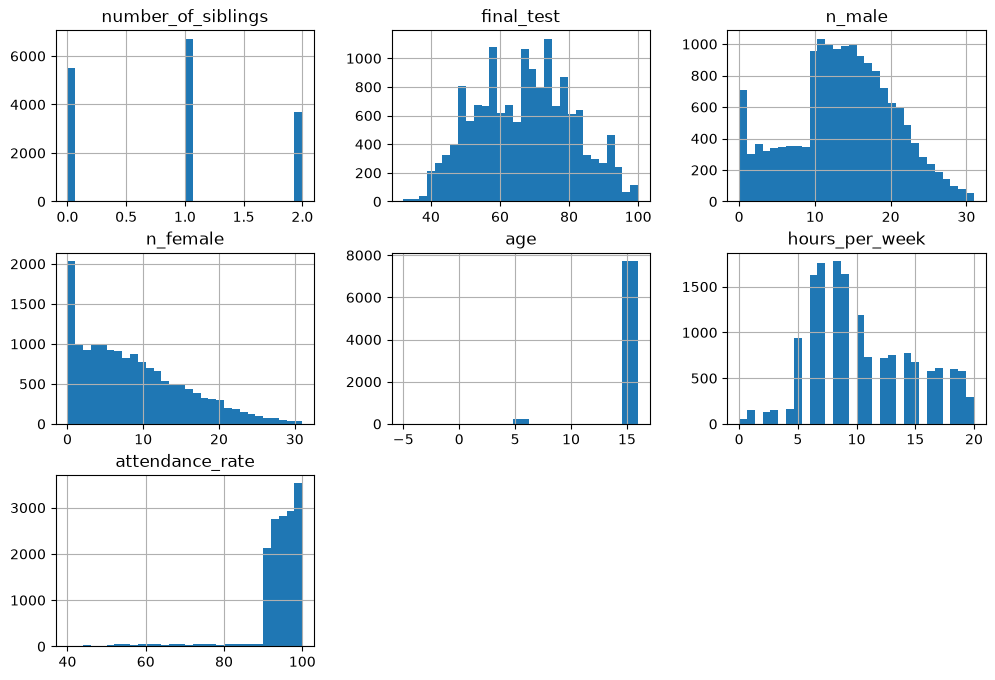

In [10]:
df[["number_of_siblings", "final_test", "n_male", "n_female", "age", "hours_per_week", "attendance_rate"]].hist(bins=30, figsize=(12,8))

## Numeric Columns vs final_test

scatter plots first, then the correlations.

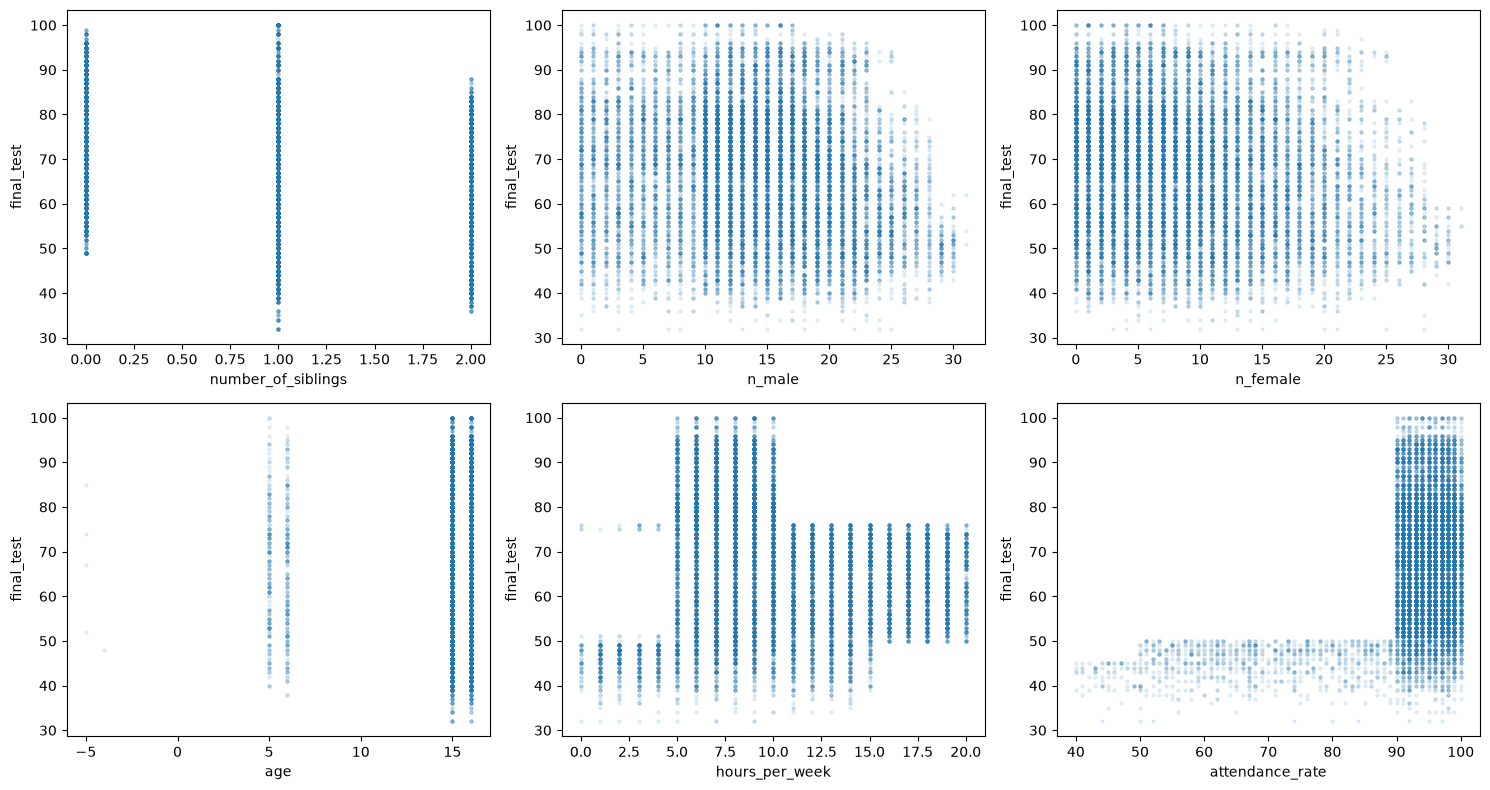

In [11]:
import matplotlib.pyplot as plt

num_cols = ["number_of_siblings", "n_male", "n_female", "age", "hours_per_week", "attendance_rate"]

fig, axes = plt.subplots(2,3, figsize=(15,8))

for ax, col in zip(axes.flatten(), num_cols):
    ax.scatter(df[col], df["final_test"], alpha=0.1, s=5)
    ax.set_xlabel(col)
    ax.set_ylabel("final_test")
plt.tight_layout()
plt.show()

In [12]:
df[num_cols + ["final_test"]].corr()["final_test"].sort_values()

number_of_siblings   -0.363767
n_female             -0.171978
n_male               -0.149152
hours_per_week       -0.148254
age                   0.014771
attendance_rate       0.349375
final_test            1.000000
Name: final_test, dtype: float64

## Categorical Columns vs final_test

boxplot per category. looking for groups whose score distribution sits
noticeably higher or lower than the rest.

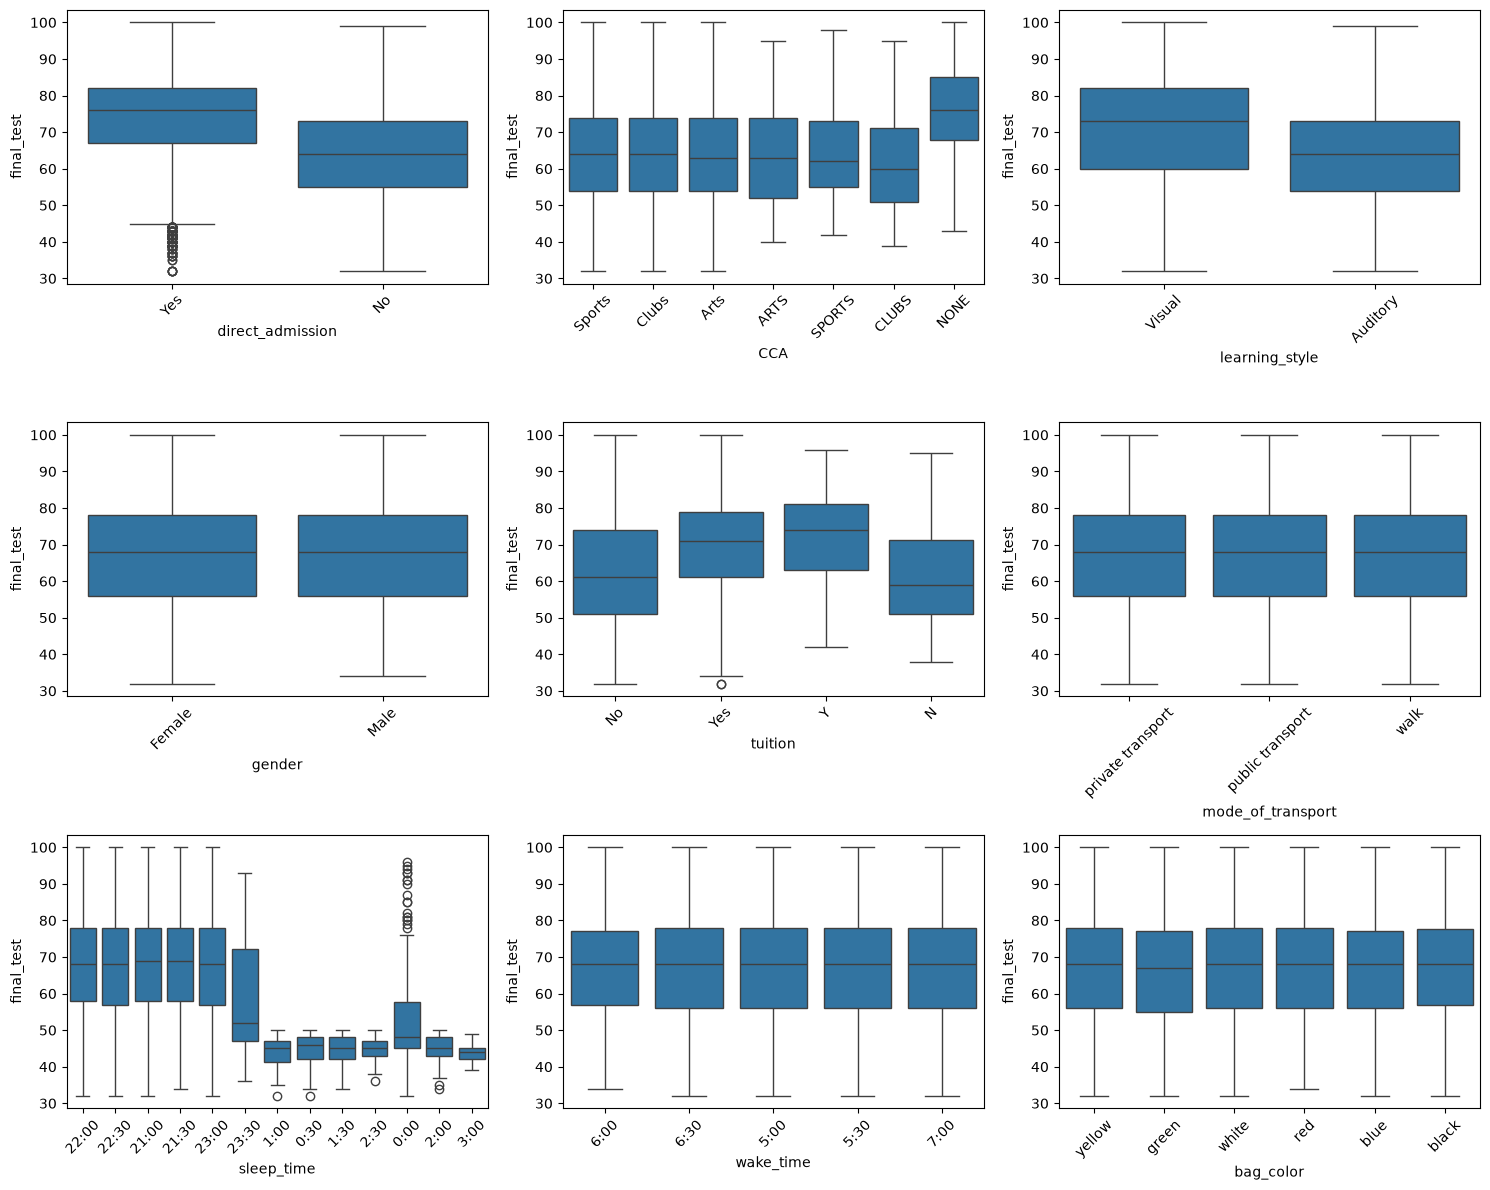

In [13]:
import seaborn as sns

cat_cols = ["direct_admission", "CCA", "learning_style", "gender", "tuition", "mode_of_transport", "sleep_time", "wake_time", "bag_color"]

fig,axes = plt.subplots(3,3, figsize=(15,12))
for ax, col in zip(axes.flatten(), cat_cols):
    sns.boxplot(x=df[col], y=df["final_test"], ax=ax)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## Data Cleaning

fixing everything spotted above: useless columns, missing targets,
inconsistent labels, and the wrong ages.

In [14]:
# index is just a row number, and rows with no final_test cant be used
df = df.drop(columns=["index"])
df = df.dropna(subset=["final_test"])

# blank CCA means no cca (see above), so it joins the NONE group
df["CCA"] = df["CCA"].str.upper().fillna("NONE")
df["tuition"] = df["tuition"].replace({"Y": "Yes", "N": "No"})

# negative ages are typos, 5 and 6 are missing the leading 1
df = df[df["age"]>0] # keep boolean mask True
df["age"] = df["age"].replace({5: 15, 6: 16})



### Duplicates

`student_id` should be unique, so any repeat is either a full duplicate row
or the same student recorded twice with slightly different values.

In [15]:
# clean up duplicates in student id
print(df["student_id"].duplicated().sum())
print(df.duplicated().sum())

846
138


In [16]:
df = df.drop_duplicates()
print(df["student_id"].duplicated().sum())

708


there are still repeated ids after dropping exact duplicates, so look at
what actually differs between those rows.

In [17]:
dup_ids = df[df["student_id"].duplicated(keep=False)]
dup_ids.sort_values("student_id").head(30)

,number_of_siblings,direct_admission,CCA,learning_style,student_id,gender,tuition,final_test,n_male,n_female,age,hours_per_week,attendance_rate,sleep_time,wake_time,mode_of_transport,bag_color
12290,0,No,CLUBS,Auditory,00811H,Female,Yes,88.0,21.0,4.0,15.0,8.0,92.0,23:00,7:00,walk,white
5534,0,No,CLUBS,Auditory,00811H,Female,Yes,88.0,21.0,4.0,15.0,8.0,92.0,23:00,7:00,walk,green
9172,0,No,CLUBS,Auditory,02RSAH,Female,Yes,64.0,12.0,9.0,15.0,17.0,97.0,22:00,6:00,private transport,green
4303,0,No,CLUBS,Auditory,02RSAH,Female,Yes,64.0,12.0,9.0,15.0,17.0,97.0,22:00,6:00,private transport,yellow
9791,0,No,ARTS,Auditory,0FC4RY,Female,No,68.0,23.0,4.0,15.0,6.0,100.0,23:00,7:00,walk,yellow
8641,0,No,ARTS,Auditory,0FC4RY,Female,No,68.0,23.0,4.0,15.0,6.0,NaN,23:00,7:00,walk,blue
6339,0,Yes,NONE,Visual,0JUGAF,Female,No,84.0,18.0,2.0,16.0,10.0,94.0,23:00,7:00,walk,yellow
1405,0,Yes,NONE,Visual,0JUGAF,Female,No,84.0,18.0,2.0,16.0,10.0,94.0,23:00,7:00,walk,red
15721,0,Yes,NONE,Auditory,0K5LDV,Female,Yes,84.0,9.0,12.0,16.0,9.0,98.0,22:00,6:00,private transport,red
9156,0,Yes,NONE,Auditory,0K5LDV,Female,Yes,84.0,9.0,12.0,16.0,9.0,98.0,22:00,6:00,private transport,white


ignoring `bag_color` and `attendance_rate`, the repeated ids seem identical.

In [18]:
print(df.drop(columns=["bag_color", "attendance_rate"]).duplicated().sum())

708


rows with a real `attendance_rate` come first and keep one row per student.

In [19]:
# na last so a row with a real attendance_rate wins over a blank one
df = df.drop(columns=["bag_color"])
df = df.sort_values("attendance_rate", na_position="last")
df =df.drop_duplicates(subset="student_id", keep="first")
print(df["student_id"].duplicated().sum())

0


### Drop columns that don't help

the boxplots for these two were equal, so they say nothing about the score.

In [20]:
df = df.drop(columns=['gender', 'mode_of_transport'])

In [21]:
df

,number_of_siblings,direct_admission,CCA,learning_style,student_id,tuition,final_test,n_male,n_female,age,hours_per_week,attendance_rate,sleep_time,wake_time
3402,1,No,CLUBS,Visual,S3GYQR,No,44.0,4.0,21.0,15.0,3.0,40.0,1:00,5:00
4981,1,Yes,SPORTS,Visual,GDSFEG,No,43.0,16.0,12.0,15.0,5.0,40.0,1:00,5:00
5693,1,No,SPORTS,Auditory,Y459JT,Yes,39.0,26.0,2.0,16.0,8.0,40.0,1:00,5:00
10833,1,No,SPORTS,Auditory,QGEIYW,Yes,43.0,15.0,9.0,16.0,3.0,40.0,1:30,5:30
13424,2,Yes,CLUBS,Visual,OGYIXN,Yes,45.0,0.0,23.0,15.0,2.0,40.0,2:30,6:30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15790,0,No,CLUBS,Auditory,GJR1LN,No,61.0,21.0,1.0,15.0,20.0,NaN,22:00,6:00
15827,0,Yes,ARTS,Visual,F90UM0,No,84.0,19.0,1.0,16.0,10.0,NaN,23:00,7:00
15832,2,No,ARTS,Auditory,D5GK79,Yes,74.0,14.0,9.0,15.0,9.0,NaN,21:00,5:00
15854,0,No,CLUBS,Auditory,05OOPM,Yes,60.0,19.0,2.0,15.0,10.0,NaN,21:00,5:00


## Feature Engineering

### class size and gender mix

combining `n_male` and `n_female` into class size (and a male ratio) to give us a better picture.

In [22]:
# total students in the class
df["class_size"] = df["n_male"] + df["n_female"]

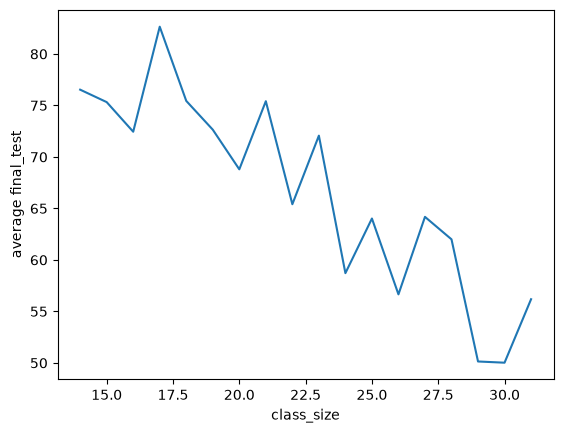

In [23]:
df.groupby("class_size")["final_test"].mean().plot()
plt.ylabel("average final_test")
plt.show()

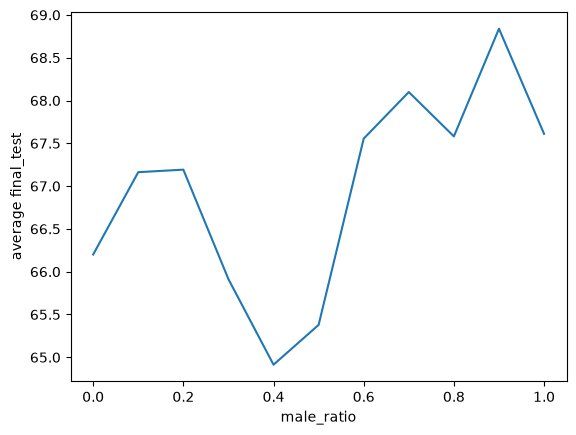

In [24]:
df["male_ratio"] = df["n_male"] / df["class_size"]
df.groupby(df["male_ratio"].round(1))["final_test"].mean().plot()
plt.ylabel("average final_test")
plt.show()

In [25]:
# class_size covers what these were saying
df = df.drop(columns=["n_female", "n_male", "male_ratio"])

### sleep hours

`sleep_time` and `wake_time` are clock times, which a model can't use directly.
turning them into hours slept is more useful.

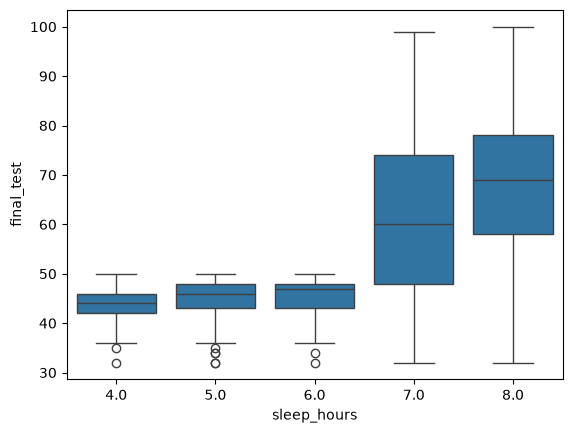

In [26]:
sleep = pd.to_datetime(df["sleep_time"], format="%H:%M")
wake = pd.to_datetime(df["wake_time"], format="%H:%M")
# mod 24 so sleeping past midnight doesn't go negative
df["sleep_hours"]=((wake - sleep).dt.total_seconds()/3600) %24

sns.boxplot(x=df["sleep_hours"], y=df["final_test"])
plt.show()

In [27]:
df = df.drop(columns=["sleep_time", "wake_time"])

In [28]:
df.head(20)

,number_of_siblings,direct_admission,CCA,learning_style,student_id,tuition,final_test,age,hours_per_week,attendance_rate,class_size,sleep_hours
3402,1,No,CLUBS,Visual,S3GYQR,No,44.0,15.0,3.0,40.0,25.0,4.0
4981,1,Yes,SPORTS,Visual,GDSFEG,No,43.0,15.0,5.0,40.0,28.0,4.0
5693,1,No,SPORTS,Auditory,Y459JT,Yes,39.0,16.0,8.0,40.0,28.0,4.0
10833,1,No,SPORTS,Auditory,QGEIYW,Yes,43.0,16.0,3.0,40.0,24.0,4.0
13424,2,Yes,CLUBS,Visual,OGYIXN,Yes,45.0,15.0,2.0,40.0,23.0,4.0
13679,1,No,SPORTS,Auditory,DZL9NZ,No,38.0,15.0,13.0,41.0,28.0,4.0
11418,1,No,CLUBS,Visual,Z9ICIM,No,43.0,16.0,5.0,41.0,30.0,4.0
6910,1,Yes,CLUBS,Auditory,E596H1,Yes,44.0,16.0,14.0,41.0,25.0,4.0
14353,1,No,ARTS,Auditory,4I4N2R,No,45.0,16.0,9.0,41.0,25.0,4.0
12638,2,No,ARTS,Auditory,O47KXI,Yes,43.0,15.0,5.0,41.0,23.0,4.0


to trace a prediction back to a student later on if needed

In [29]:
df.to_csv("data/cleaned.csv", index=False)
df = df.drop(columns=["student_id"])

### correlation with finalised columns

In [30]:
num_cols = ["number_of_siblings", "age", "hours_per_week", "attendance_rate", "class_size", "sleep_hours"]
df[num_cols + ["final_test"]].corr()["final_test"].sort_values()

class_size           -0.503679
number_of_siblings   -0.360933
hours_per_week       -0.150675
age                   0.003102
sleep_hours           0.325093
attendance_rate       0.346207
final_test            1.000000
Name: final_test, dtype: float64

## A Closer Look

the correlations above are only fair to a straight line relationship. three of
these columns turn out not to be straight lines at all, so a plain correlation
number is misleading for them.

### hours_per_week

correlation says -0.15, which would mean studying more gets you a worse score.
that doesn't sound right, so look at the average at each value first and let the
shape decide how to group it.

In [31]:
# average score at every single hours_per_week value, before deciding on any grouping
df.groupby("hours_per_week")["final_test"].agg(["mean", "count"]).round(1)

,mean,count
hours_per_week,,
0.0,47.5,51
1.0,45.0,130
2.0,46.4,126
3.0,46.8,132
4.0,47.0,139
5.0,70.8,852
6.0,72.6,1500
7.0,72.9,1616
8.0,72.5,1622


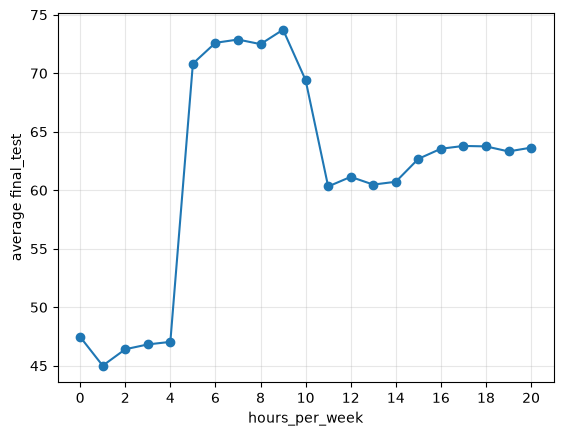

In [32]:
df.groupby("hours_per_week")["final_test"].mean().plot(marker="o")
plt.ylabel("average final_test")
plt.xlabel("hours_per_week")
plt.xticks(range(0, 21, 2))
plt.grid(alpha=0.3)
plt.show()

three flat stretches with two jumps between them, so the cut points come from
the table above rather than being picked out of the air:

- 0 to 4 hours sits around 45-47
- jumps to about 70-74 at 5 hours, and stays there until 10
- drops to about 60-64 at 11 hours, and stays there to 20

grouping it that way to see the sizes and the spread.

In [33]:
df["hrs_band"] = pd.cut(df["hours_per_week"], [-1, 4, 10, 20], labels=["0-4", "5-10", "11-20"])
print(df.groupby("hrs_band", observed=True)["final_test"].agg(["mean", "std", "count"]).round(1))
print()

# if the -0.15 were real, the correlation would stay negative inside each band
print("correlation within each band")
for band, g in df.groupby("hrs_band", observed=True):
    print(f"  {band:<6} {g['hours_per_week'].corr(g['final_test']):.3f}")

          mean   std  count
hrs_band                   
0-4       46.4   7.0    578
5-10      72.2  14.7   8190
11-20     62.1   8.8   5786

correlation within each band
  0-4    0.057
  5-10   -0.014
  11-20  0.143


so it's an upside down U, best around 5-10 hours. inside each band the
correlation is flat or slightly positive, so the negative number is only there
because the 11-20 group sits lower than the 5-10 group, not because studying
more hurts.

could just be that the 0-4 group are students who have other things going on.
check that the shape isn't just attendance and siblings in disguise.

In [34]:
# hold attendance and siblings roughly still, then compare the bands
df["att_band"] = pd.cut(df["attendance_rate"], [0, 90, 95, 100])

print("mean final_test")
print(df.pivot_table(index=["att_band", "number_of_siblings"], columns="hrs_band",
                     values="final_test", aggfunc="mean", observed=True).round(1))
print()
print("students in each cell")
print(df.pivot_table(index=["att_band", "number_of_siblings"], columns="hrs_band",
                     values="final_test", aggfunc="count", observed=True))

mean final_test
hrs_band                       0-4  5-10  11-20
att_band  number_of_siblings                   
(0, 90]   0                   49.0  80.4   64.4
          1                   45.8  54.3   51.3
          2                   42.9  53.7   54.3
(90, 95]  0                   66.8  79.9   67.0
          1                   47.7  68.0   60.0
          2                   44.5  68.4   63.6
(95, 100] 0                   66.8  80.3   67.0
          1                   47.9  68.0   60.0
          2                   43.3  69.5   63.8

students in each cell
hrs_band                      0-4  5-10  11-20
att_band  number_of_siblings                  
(0, 90]   0                     1   198     64
          1                   165   411    300
          2                    83   193    140
(90, 95]  0                    12  1635    700
          1                   104  1342   1131
          2                    42   706    729
(95, 100] 0                     6  1443    719
          

5-10 is the highest in every single row, so the shape holds up. keeping the
column, but a linear model won't be able to use it properly. a tree will.

### number_of_siblings

correlation -0.36, but check whether it actually goes down step by step.

In [35]:
df.groupby("number_of_siblings")["final_test"].agg(["mean", "count"]).round(1)

,mean,count
number_of_siblings,,
0,76.0,5013
1,61.9,6147
2,63.9,3394


not a steady drop. 1 sibling is lower than 2. the real split is having no
siblings versus having any, so "more siblings, lower score" isn't the right way
to say it.

### age

correlation is basically zero after the typos were fixed. before dropping it,
check it isn't hiding inside a subgroup.

In [36]:
print(df.groupby("age")["final_test"].mean().round(2))
print()

# does age matter within any one group?
for col in ["tuition", "direct_admission", "learning_style", "number_of_siblings"]:
    t = df.pivot_table(index=col, columns="age", values="final_test", aggfunc="mean").round(1)
    t["gap"] = (t[16.0] - t[15.0]).round(1)
    print(t[["gap"]].T.rename(index={"gap": col}))

age
15.0    67.15
16.0    67.23
Name: final_test, dtype: float64

tuition   No  Yes
age              
tuition -0.4  0.6
direct_admission   No  Yes
age                       
direct_admission  0.0  0.4
learning_style  Auditory  Visual
age                             
learning_style       0.3    -0.3
number_of_siblings    0    1    2
age                              
number_of_siblings  0.5 -0.3  0.2


every gap is under a mark. age carries nothing on its own or in combination.
leaving it in as a feature anyway, so the model's feature importance can show
it lands at the bottom.

### missing attendance_rate

the nulls get filled in later, during training, using the median of the
training rows only. before that, check whether being missing is itself a
pattern, because if the gaps cluster in one group then filling them hides
something.

In [37]:
print("missing attendance_rate by study band")
print(df.assign(missing=df["attendance_rate"].isna())
        .groupby("hrs_band", observed=True)["missing"].mean().round(3))
print()
print("by siblings")
print(df.assign(missing=df["attendance_rate"].isna())
        .groupby("number_of_siblings")["missing"].mean().round(3))

missing attendance_rate by study band
hrs_band
0-4      0.050
5-10     0.048
11-20    0.044
Name: missing, dtype: float64

by siblings
number_of_siblings
0    0.047
1    0.046
2    0.046
Name: missing, dtype: float64


about the same rate everywhere, so the gaps look random and the median is a
safe fill. still adding a missing/not missing flag during training so the model
can tell a filled value apart from a real one.

In [38]:
# tidy up the columns that were only for looking at
df = df.drop(columns=["hrs_band", "att_band"])
df.head()

,number_of_siblings,direct_admission,CCA,learning_style,tuition,final_test,age,hours_per_week,attendance_rate,class_size,sleep_hours
3402,1,No,CLUBS,Visual,No,44.0,15.0,3.0,40.0,25.0,4.0
4981,1,Yes,SPORTS,Visual,No,43.0,15.0,5.0,40.0,28.0,4.0
5693,1,No,SPORTS,Auditory,Yes,39.0,16.0,8.0,40.0,28.0,4.0
10833,1,No,SPORTS,Auditory,Yes,43.0,16.0,3.0,40.0,24.0,4.0
13424,2,Yes,CLUBS,Visual,Yes,45.0,15.0,2.0,40.0,23.0,4.0


### The columns that behave normally

the boxplots earlier showed these have an effect, but not the actual numbers.
printing them so the write up has something to quote.

In [39]:
for col in ["direct_admission", "learning_style", "tuition", "CCA"]:
    print(df.groupby(col)["final_test"].agg(["mean", "count"]).round(1))
    print()

                  mean  count
direct_admission             
No                65.0  10271
Yes               72.5   4283

                mean  count
learning_style             
Auditory        63.9   8376
Visual          71.6   6178

         mean  count
tuition             
No       62.9   6304
Yes      70.5   8250

        mean  count
CCA                
ARTS    64.1   3593
CLUBS   63.9   3707
NONE    76.8   3616
SPORTS  64.1   3638



all four split the students into a clearly better and a clearly worse group,
and all four are simple yes/no style columns, so a linear model can use them
without any trouble.

### sleep_hours

worth checking the new feature is actually worth keeping.

In [40]:
print(df.groupby("sleep_hours")["final_test"].agg(["mean", "count"]).round(1))
print()
print("share of students at each value")
print(df["sleep_hours"].value_counts(normalize=True).sort_index().round(3))

             mean  count
sleep_hours             
4.0          43.8    136
5.0          45.1    214
6.0          45.6    218
7.0          61.6    598
8.0          68.4  13388

share of students at each value
sleep_hours
4.0    0.009
5.0    0.015
6.0    0.015
7.0    0.041
8.0    0.920
Name: proportion, dtype: float64


more sleep, better score, and it does move in one direction. but 92% of
students sit at 8 hours, so it is really splitting off a small group of tired
students rather than telling us much about everyone else. keeping it, just not
leaning on it.

### attendance_rate

the nulls get filled with the median later. checking the shape to make sure
median is the right choice rather than mean.

count    13880.0
mean        93.3
std          7.9
min         40.0
25%         92.0
50%         95.0
75%         97.0
max        100.0
Name: attendance_rate, dtype: float64

mean vs median
  mean   93.3
  median 95.0


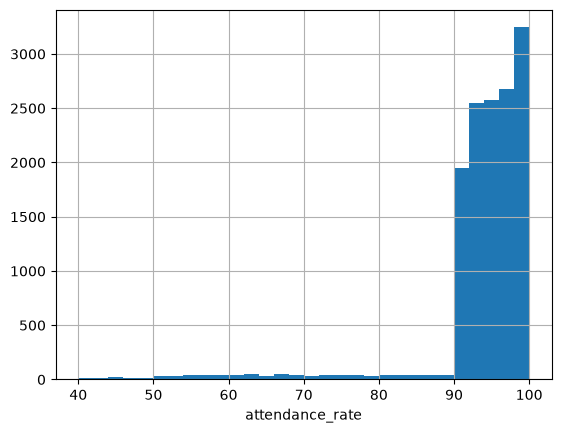

In [41]:
print(df["attendance_rate"].describe().round(1))
print()
print("mean vs median")
print(f"  mean   {df['attendance_rate'].mean():.1f}")
print(f"  median {df['attendance_rate'].median():.1f}")
df["attendance_rate"].hist(bins=30)
plt.xlabel("attendance_rate")
plt.show()

most students are in the 90s with a thin tail running down to 40, so the mean
gets pulled below the middle of the data. median is the safer fill, and the low
attendance students are exactly the ones the school wants flagged so it matters
not to distort them.

### sleep_hours and attendance_rate are nearly the same column

the trained model gives sleep_hours almost no importance even though the
averages above look like a real effect. checking whether another column is
already saying the same thing.

In [42]:
print("correlation of sleep_hours with the other numeric columns")
num = ["class_size", "number_of_siblings", "hours_per_week", "attendance_rate", "age", "final_test"]
print(df[num + ["sleep_hours"]].corr()["sleep_hours"].drop("sleep_hours").round(3))
print()
print("attendance_rate at each sleep_hours value")
print(df.groupby("sleep_hours")["attendance_rate"].agg(["mean", "min", "max", "count"]).round(1))

correlation of sleep_hours with the other numeric columns
class_size           -0.149
number_of_siblings   -0.107
hours_per_week        0.123
attendance_rate       0.886
age                  -0.014
final_test            0.325
Name: sleep_hours, dtype: float64

attendance_rate at each sleep_hours value
             mean   min    max  count
sleep_hours                          
4.0          49.5  40.0   63.0    131
5.0          58.3  46.0   74.0    204
6.0          67.3  56.0   82.0    209
7.0          87.1  66.0   94.0    575
8.0          95.0  76.0  100.0  12761


0.886 against attendance_rate, and the ranges barely overlap: students on 4
hours of sleep have attendance between 40 and 63, students on 8 hours are
between 76 and 100. low sleep and high attendance basically does not occur.

so the question is whether sleep_hours says anything once attendance is known.

In [43]:
att_band = pd.cut(df["attendance_rate"], [0, 80, 90, 95, 100])

print("mean final_test")
print(df.pivot_table(index=att_band, columns="sleep_hours", values="final_test",
                     aggfunc="mean", observed=True).round(1))
print()
print("counts")
print(df.pivot_table(index=att_band, columns="sleep_hours", values="final_test",
                     aggfunc="count", observed=True))

mean final_test
sleep_hours       4.0   5.0   6.0   7.0   8.0
attendance_rate                              
(0, 80]          43.8  45.1  45.7  45.5  46.1
(80, 90]          NaN   NaN  43.5  60.5  65.3
(90, 95]          NaN   NaN   NaN  68.6  68.6
(95, 100]         NaN   NaN   NaN   NaN  68.6

counts
sleep_hours        4.0    5.0    6.0    7.0     8.0
attendance_rate                                    
(0, 80]          131.0  204.0  205.0  126.0    24.0
(80, 90]           NaN    NaN    4.0  141.0   720.0
(90, 95]           NaN    NaN    NaN  308.0  6093.0
(95, 100]          NaN    NaN    NaN    NaN  5924.0


within the lowest attendance band the scores run 43.8, 45.1, 45.7, 45.5, 46.1
across 4 to 8 hours of sleep. flat. the empty cells say the rest: there is no
such thing here as a student who sleeps little and attends often.

so sleep_hours is close to a restatement of attendance_rate, which is why the
forest leans on attendance (0.057) and ignores sleep (0.002). keeping it, since
it costs nothing, but it is not an independent signal. given the brief warns
about synthetic features, a link this tight is worth flagging as probably built
into the data rather than found in it.